# Null testing an asphere with a computer-generated hologram

A concave asphere is measured in a Fizeau interferometer against the
spherical wave of a transmission sphere (TS), as the sphere in
notebook 502 (radius interferometer). An asphere departs from every sphere, by tens to
hundreds of waves, so it returns far more fringes than a camera resolves,
and its rays come back on other paths than they went: the interferometer's
own errors no longer cancel (retrace error). A **null test** reshapes the
test wave into the shape of the asphere so that a perfect surface gives no
fringes at all. Since Wyant and Bennett (1972) the usual null corrector for
aspheres is a **computer-generated hologram** (CGH): a pattern of lines
written with an e-beam or laser writer on a fused silica plate, whose
diffraction order +1 turns the spherical wave of the TS into a wave that
meets the asphere everywhere at normal incidence.

This notebook goes through the whole chain:

1. why a null is needed: the asphere in the plain spherical wave;
2. the **design** of the CGH phase from the normals of the asphere,
   traced exactly (`cgh.null_phase()`), and the choice of the spacing;
3. the other **diffraction orders**: a tilt carrier separates them, the
   interferometer's stop blocks them, and the ones that slip through are
   field traced into ghost fringes;
4. **alignment zones** around the null region: a Littrow ring that aligns
   the CGH to the interferometer and a cat's eye ring that sets the
   spacing to the asphere;
5. the **measurement**: a misaligned asphere with a form error, phase
   shifting interferograms;
6. the **reconstruction** of the surface form deviation (SFD): removing
   the misalignment with traced sensitivities, mapping the camera onto the
   surface, Zernikes of the surface;
7. the **error budget** of the CGH itself: line placement (writer
   distortion), etch depth and duty cycle (scalar and rigorous), substrate.

The tools are `raytrace.ZernikePhaseSurface` (a diffractive surface with a
linear carrier and a Zernike phase), the module `pyoptics.cgh` (design,
orders, alignment zones, fabrication errors, reconstruction), the
unfolded double pass of `raytrace.double_pass()`, the field tracing of
notebook 460 (field tracing) and the fringe analysis of
notebook 500 (interferometry). VirtualLab Fusion has a use case on the first step (an
idealized diffractive lens that compensates an asphere, optimized for the
spot size); here the hologram phase follows directly from the geometry, and
the chain continues to the measured surface.

In [1]:
import copy
import time

import numpy as np
import matplotlib.pyplot as plt
from numpy import pi

from pyoptics import cgh, sketch
from pyoptics import fieldtrace as ft
from pyoptics.interferometry import interferogram, phase_shifts, psi_hariharan
from pyoptics.processing import CameraNoiser
from pyoptics.raytrace import (Surface, System, ZernikePhaseSurface, ZernikeSurface, double_pass,
                               fused_silica)
from pyoptics.unwrap import unwrap

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})
T_START = time.time()

## 0. The setup

The collimated beam of the interferometer (25 mm radius, HeNe) enters the
TS. Its last surface is concentric with the focus and reflects the
reference wave back into the interferometer. The test wave converges
through the CGH, a 6.35 mm fused silica plate with the pattern on the side
facing the asphere. The pattern has a **tilt carrier** of 60 lines/mm: its
order +1 leaves the plate tilted by 2.2°, focuses beside the TS focus and
travels on to the asphere, which sits on that tilted axis. On the way back
the light diffracts once more into +1 and returns on its own path. The
orders 0 and -1 (and all others) go elsewhere.

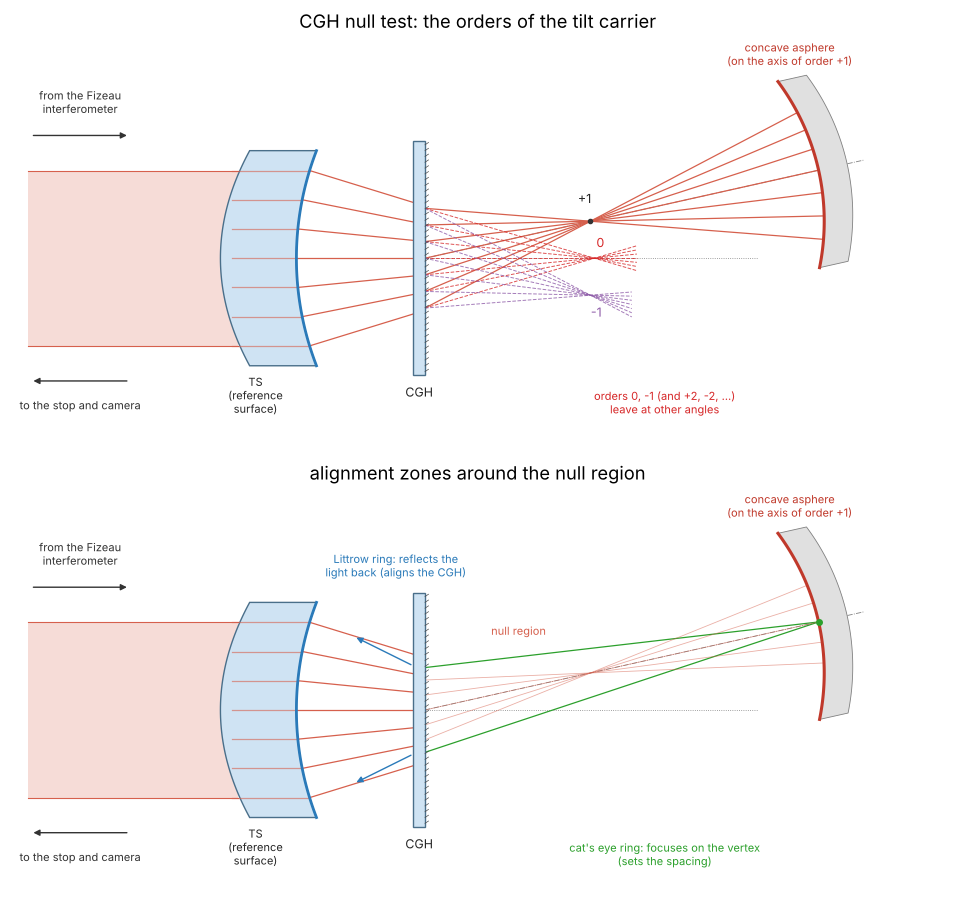

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9.2))
sketch.cgh_null_test(axes[0], title="CGH null test: the orders of the tilt carrier")
sketch.cgh_null_test(axes[1], show="zones", title="alignment zones around the null region")
plt.tight_layout()

The TS is the stigmatic singlet of notebook 502 (radius interferometer):
an ellipsoidal front surface with $K=-1/n^2$ focuses the collimated beam
without aberrations, the reference surface is concentric with the focus.
At $F = 75$ mm and 25 mm beam radius it has NA 0.32.

The asphere is a concave hyperboloid with a fourth order term, 68 mm clear
aperture, vertex radius 120 mm:

$$z(r) = \frac{c r^2}{1 + \sqrt{1 - (1 + K) c^2 r^2}} + A_4 r^4,\quad
R = -120\ \text{mm},\ K = -1.3,\ A_4 = -2\cdot 10^{-9}\ \text{mm}^{-3}.$$

In [3]:
WL = 632.8e-6        # mm
N_TS = fused_silica(632.8)
A = 25.0             # beam radius of the interferometer
F = 75.0             # TS focus behind its first vertex
R1 = F*(N_TS - 1)/N_TS
T1 = 12.0
R2 = F - T1          # reference surface, concentric with the focus
D_CGH = 45.0         # CGH pattern this far in front of the TS focus
T_CGH = 6.35         # CGH substrate thickness
SD_CGH = 25.0
R0, K, A4 = -120.0, -1.3, -2e-9   # the asphere
A_TEST = 34.0        # its clear aperture radius
CARRIER = 60.0       # lines/mm
DET = -10.0          # camera plane (collimated space, conjugate to the CGH in a real instrument)


def ts(reference_arm=False):
    s1 = Surface(R1, T1, material=fused_silica, conic=-1/N_TS**2, semi_diameter=A, label="TS")
    if reference_arm:
        return [s1, Surface(R2, mirror=True, semi_diameter=A, label="reference")]
    return [s1, Surface(R2, F - D_CGH - T_CGH - T1, n_after=1.0, semi_diameter=A, label="reference")]


def forward(hologram, dz=0.0, decenter=(0.0, 0.0), tilt=(0.0, 0.0), sfd=None):
    # TS, CGH substrate, CGH pattern and the asphere on the axis of the order +1.
    # dz: spacing change; decenter, tilt: misalignment of the asphere in its frame;
    # sfd: Fringe Zernike form error {j: sag in mm} of the asphere
    theta = np.arcsin(WL*hologram.carrier[1]*hologram.order)
    L = D_CGH + abs(R0) + dz  # CGH to asphere vertex along the tilted axis
    substrate = Surface(np.inf, T_CGH, material=fused_silica, semi_diameter=SD_CGH, label="CGH substrate")
    h = copy.copy(hologram)
    h.thickness, h.n_after = L*np.cos(theta), 1.0
    kw = dict(conic=K, aspheric=(A4,), mirror=True, semi_diameter=A_TEST, label="asphere",
              decenter=(decenter[0], L*np.sin(theta) + decenter[1]), tilt=(-theta + tilt[0], tilt[1], 0.0))
    asphere = (Surface(R0, **kw) if sfd is None
               else ZernikeSurface(R0, zernike=sfd, norm_radius=A_TEST, **kw))
    return ts() + [substrate, h, asphere]


def forward_system(hologram, **kw):
    return System(forward(hologram, **kw), 0, WL, entrance_pupil_radius=A, ray_aiming=False)


def test_arm(hologram, **kw):
    return System(double_pass(forward(hologram, **kw), image_distance=DET), 0, WL, ray_aiming=False)


CGH, ASPHERE = 3, 4      # indices in the forward pass; the return pass meets the CGH at 5
reference_arm = System(double_pass(ts(reference_arm=True), image_distance=DET), 0, WL, ray_aiming=False)
xc = np.linspace(-A, A, 257)   # camera grid (mm, in the collimated beam)
XC, YC = np.meshgrid(xc, xc)
ext = [xc[0], xc[-1], xc[0], xc[-1]]
ref_map = reference_arm.ray_map(xc, xc, field=0.0, N=161)
print("TS: R1 = {:.3f} mm (K = {:.4f}), reference surface R2 = {:.1f} mm, NA = {:.3f}".format(
    R1, -1/N_TS**2, R2, A/np.hypot(A, F)))

TS: R1 = 23.525 mm (K = -0.4711), reference surface R2 = 63.0 mm, NA = 0.316


## 1. Why a null: the asphere in the spherical test wave

Without the CGH, the asphere is best placed with its best fit sphere
concentric with the TS focus. Its departure from that sphere is the
interferogram, twice over: the ray trace of the double pass shows how
much.

departure from the best fit sphere: 30.4 um PV = 48 waves; 94 waves PV in the double pass
up to 40 fringes/mm on the camera, i.e. 2 fringes per pixel of a 1k camera


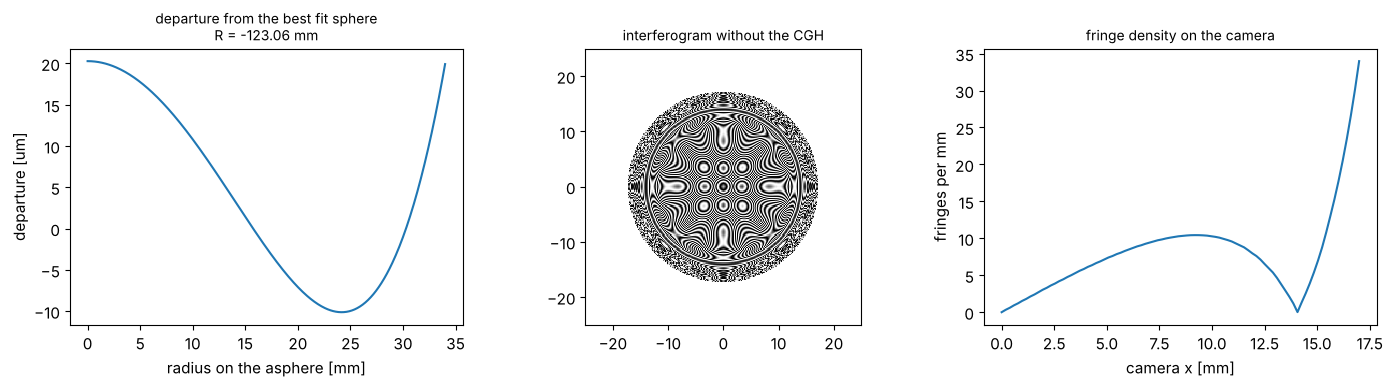

In [4]:
asph = Surface(R0, conic=K, aspheric=(A4,))
r = np.linspace(0, A_TEST, 400)
z = asph.sag(r**2)
# best fit sphere: least squares over the aperture (area weighted), piston free
best = None
for R_bfs in np.linspace(-130, -115, 3001):
    c = 1/R_bfs
    dev = z - c*r**2/(1 + np.sqrt(1 - c**2*r**2))
    dev -= np.average(dev, weights=r)
    rms = np.sqrt(np.average(dev**2, weights=r))
    if best is None or rms < best[0]:
        best = (rms, R_bfs, dev)
rms_bfs, R_BFS, dev = best

# the asphere without the CGH, its best fit sphere centred on the TS focus
no_cgh = [ts()[0], Surface(R2, 0.0, n_after=1.0, semi_diameter=A, label="reference")]
no_cgh[1].thickness = R2 + abs(R_BFS)
no_cgh.append(Surface(R0, conic=K, aspheric=(A4,), mirror=True, semi_diameter=A_TEST))
plain = System(double_pass(no_cgh, image_distance=DET), 0, WL, ray_aiming=False)
m_plain = plain.ray_map(xc, xc, field=0.0, N=161)
phi_plain = 2*pi*(m_plain.opl - ref_map.opl)/WL
ok_plain = m_plain.mask & ref_map.mask
phi_plain -= np.nanmean(phi_plain[ok_plain])
gy, gx = np.gradient(np.where(ok_plain, phi_plain, np.nan), xc, xc)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(r, 1e3*dev)
axes[0].set_xlabel("radius on the asphere [mm]")
axes[0].set_ylabel("departure [um]")
axes[0].set_title("departure from the best fit sphere\nR = {:.2f} mm".format(R_BFS), fontsize=10)
axes[1].imshow(np.where(ok_plain, interferogram(phi_plain), np.nan), extent=ext, origin="lower", cmap="gray",
               interpolation="none")
axes[1].set_title("interferogram without the CGH", fontsize=10)
axes[2].plot(xc[128:], np.hypot(gx, gy)[128, 128:]/(2*pi))
axes[2].set_xlabel("camera x [mm]")
axes[2].set_ylabel("fringes per mm")
axes[2].set_title("fringe density on the camera", fontsize=10)
plt.tight_layout()
print("departure from the best fit sphere: {:.1f} um PV = {:.0f} waves; {:.0f} waves PV in the double pass".format(
    1e3*np.ptp(dev), np.ptp(dev)/WL, np.ptp(phi_plain[ok_plain])/(2*pi)))
print("up to {:.0f} fringes/mm on the camera, i.e. {:.0f} fringes per pixel of a 1k camera".format(
    np.nanmax(np.hypot(gx, gy)[ok_plain])/(2*pi), np.nanmax(np.hypot(gx, gy)[ok_plain])/(2*pi)*2*A/1000))

The interferogram aliases badly (the gray image above shows moiré, not the
fringes): a camera needs at least two pixels per fringe. Even with a
camera fine enough, the rays return on other paths through the TS than they
went (the asphere reflects them off its normals), so the TS errors would not
cancel and the measurement would need a full model of the interferometer.
A null removes both problems.

## 2. Designing the CGH

The measuring wave must meet the asphere at normal incidence, so it travels
along the asphere's normals. Cast a normal from a point $Q$ of the asphere
back to the CGH: it arrives at the point $C$ after the optical path
$L(C) = n|Q - C|$. The incoming wave reaches $C$ with the optical path
$\mathrm{OPL_{in}}(C)$ (through the TS and the substrate, traced). The CGH
adds $m\lambda\varphi/2\pi$ in the order $m$, so all rays arrive at the
asphere in phase if

$$\frac{m\lambda}{2\pi}\,\varphi(C) = -\left(\mathrm{OPL_{in}}(C) + L(C)\right) + \text{const}.$$

This is exact (Fermat): the gradient of $\varphi$ then bends every
incoming ray along its normal. `cgh.null_phase()` evaluates it for a
grid of normals and fits the phase minus the carrier with Zernikes on the
CGH. No optimization is needed, unlike a design that minimizes the spot
size of the returning light.

**The spacing.** The tilt carrier fixes the direction to the asphere, not
the distance. The CGH can absorb a defocus, so every spacing works, but the
phase that is left after the carrier differs. Its steepest slope, the
largest local line frequency apart from the carrier, should be small: it
decides how far the unwanted orders spread and how close they come to the
measuring one (section 3). A scan of the spacing finds the balance between
the asphere's spherical aberration and defocus.

chosen spacing change +7.0 mm: 16.7 lines/mm besides the 60 lines/mm carrier


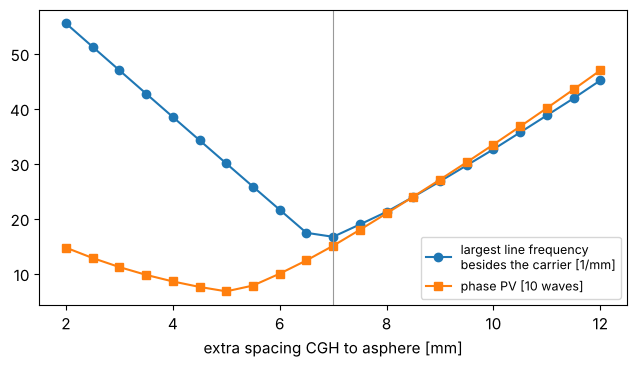

In [5]:
blank = ZernikePhaseSurface(carrier=(0.0, CARRIER), semi_diameter=SD_CGH, label="CGH")
spacings = np.arange(2.0, 12.1, 0.5)
f_max, pv = [], []
for dz in spacings:
    d = cgh.null_phase(forward_system(blank, dz=dz), CGH, ASPHERE, N=41, terms=66)
    gx, gy = d.surface.phase_gradient(d.x, d.y, carrier=False)
    f_max.append(np.max(np.hypot(gx - gx.mean(), gy - gy.mean()))/(2*pi))
    pv.append(np.ptp(d.surface.phase_at(d.x, d.y, carrier=False))/(2*pi))
DZ = spacings[int(np.argmin(f_max))]

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(spacings, f_max, "o-", label="largest line frequency\nbesides the carrier [1/mm]")
ax.plot(spacings, np.array(pv)/10, "s-", label="phase PV [10 waves]")
ax.axvline(DZ, color="0.6", lw=0.8)
ax.set_xlabel("extra spacing CGH to asphere [mm]")
ax.legend(fontsize=9)
plt.tight_layout()
print("chosen spacing change {:+.1f} mm: {:.1f} lines/mm besides the {:.0f} lines/mm carrier".format(
    DZ, min(f_max), CARRIER))

The steepest slope is smallest where defocus balances the spherical
aberration of the asphere at the rim, not where the phase PV is smallest.
At that spacing the design converges quickly with the number of Zernike
terms. The fit residual is of the phase of one pass; the real check is to
trace the double pass and compare it with the reference arm.

In [6]:
fsys = forward_system(blank, dz=DZ)
for terms in (37, 66, 120, 231):
    d = cgh.null_phase(fsys, CGH, ASPHERE, N=81, terms=terms)
    print("{:4d} Noll terms (radial order {:2d}): fit residual {:.1e} waves rms".format(
        terms, int(np.ceil((np.sqrt(8*terms + 1) - 3)/2)), d.fit_residual))
design = d
hologram = design.surface

T0 = test_arm(hologram, dz=DZ)
m0 = T0.ray_map(xc, xc, field=0.0, N=161, surface=ASPHERE)
phi0 = 2*pi*(m0.opl - ref_map.opl)/WL
pupil = m0.mask & ref_map.mask
phi0 -= np.mean(phi0[pupil])
print("traced double pass: null residual {:.1e} waves rms, {:.1e} waves PV".format(
    np.std(phi0[pupil])/(2*pi), np.ptp(phi0[pupil])/(2*pi)))

  37 Noll terms (radial order  8): fit residual 9.2e-03 waves rms
  66 Noll terms (radial order 10): fit residual 1.4e-03 waves rms


 120 Noll terms (radial order 14): fit residual 4.0e-05 waves rms
 231 Noll terms (radial order 20): fit residual 2.7e-07 waves rms


traced double pass: null residual 4.9e-07 waves rms, 6.3e-06 waves PV


The traced null is perfect to $10^{-6}$ waves, limited by the
interpolation of the ray map. With fewer terms (a Fringe set of 37) the
residual is a fraction of a wave, which a real design cannot afford: the CGH
is the reference of the test, its design error goes straight into the
measured surface.

What does the CGH look like? The local period $2\pi/|\nabla\varphi|$ must
stay well above the resolution of the writer (and above a few wavelengths,
where the scalar picture of the diffraction efficiency holds, section 7).

local period 13.4 ... 24.6 um over the null region (radius 13.02 mm)


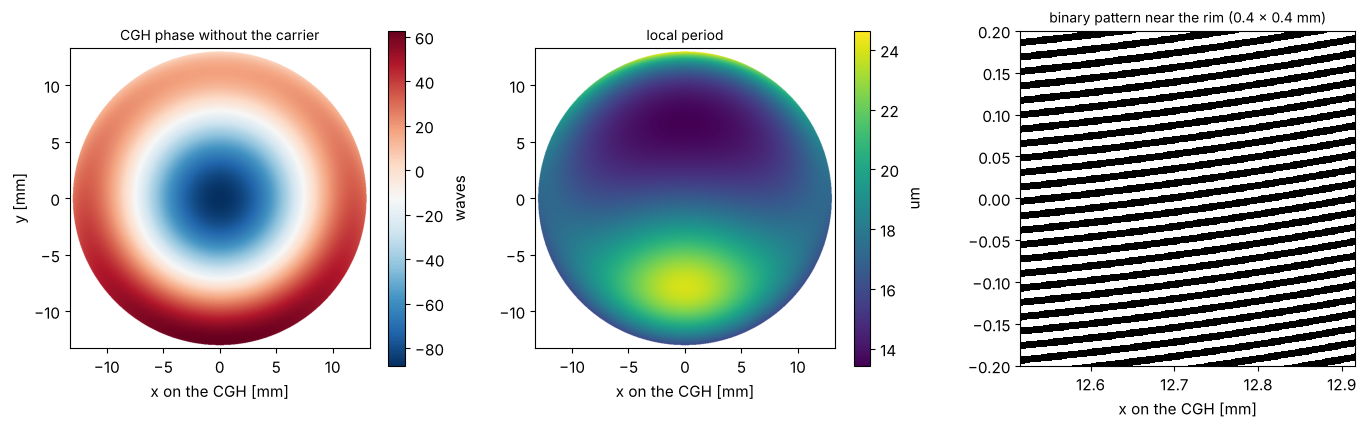

In [7]:
rn = design.norm_radius
s = np.linspace(-1.02*rn, 1.02*rn, 801)
SX, SY = np.meshgrid(s, s)
inside = np.hypot(SX - hologram.centre[0], SY - hologram.centre[1]) <= rn
period = np.where(inside, hologram.local_period(SX, SY), np.nan)
phase_map = hologram.phase_at(SX, SY)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
im = axes[0].imshow(np.where(inside, hologram.phase_at(SX, SY, carrier=False)/(2*pi), np.nan),
                    extent=[s[0], s[-1], s[0], s[-1]], origin="lower", cmap="RdBu_r")
plt.colorbar(im, ax=axes[0], label="waves")
axes[0].set_title("CGH phase without the carrier", fontsize=10)
im = axes[1].imshow(1e3*period, extent=[s[0], s[-1], s[0], s[-1]], origin="lower", cmap="viridis")
plt.colorbar(im, ax=axes[1], label="um")
axes[1].set_title("local period", fontsize=10)
zx = np.linspace(rn - 0.5, rn - 0.1, 600)
zy = np.linspace(-0.2, 0.2, 600)
ZX, ZY = np.meshgrid(zx, zy)
axes[2].imshow(cgh.binary_mask(hologram.phase_at(ZX, ZY)), cmap="gray_r",
               extent=[zx[0], zx[-1], zy[0], zy[-1]], origin="lower", interpolation="none")
axes[2].set_title("binary pattern near the rim (0.4 x 0.4 mm)", fontsize=10)
for ax in axes:
    ax.set_xlabel("x on the CGH [mm]")
axes[0].set_ylabel("y [mm]")
plt.tight_layout()
print("local period {:.1f} ... {:.1f} um over the null region (radius {:.2f} mm)".format(
    1e3*np.nanmin(period), 1e3*np.nanmax(period), rn))

The lines are curved and their spacing varies by a factor of two around
the carrier's 16.7 µm, well within the reach of laser writers.

**The mapping.** Each point of the CGH sends its ray to one point of the
asphere: `null_phase()` returns this mapping as `test_points`. The camera
sees the CGH (through the TS); the asphere appears distorted on it. Section 6
needs this.

## 3. The other orders and the interferometer's stop

A binary hologram diffracts into many orders; each pass through the CGH
picks one. Of all combinations $(m_1, m_2)$ (forward, return) only $(+1,
+1)$ is the null. The tilt carrier gives the others a tilt: the return
beam of $(m_1, m_2)$ leaves with roughly $(m_1 + m_2 - 2)$ times the
carrier tilt (mapped through the TS) and focuses beside the stop in the
focus of the interferometer. `cgh.order_paths()` traces all combinations
and reports the slopes at which the rays leave.

The weak spot are the combinations with $m_1 + m_2 = 2$: $(0, 2)$ and $(2,
0)$ have the same carrier as the null. They are separated only by the
remaining phase, i.e. by defocus and aberration, and part of their light
passes the stop. Here the stop has the radius 2.5 mm in the 500 mm focus of
the collimator, an acceptance of 5 mrad.

36 combinations traced in 1.7 s
  (-2, -1):   0.1% of the null's rays pass the stop
   (-2, 3):   6.4% of the null's rays pass the stop
  (-1, -1):   0.1% of the null's rays pass the stop
   (-1, 3):   2.5% of the null's rays pass the stop
    (0, 2):  47.3% of the null's rays pass the stop
    (0, 3):   1.2% of the null's rays pass the stop
    (1, 1): 100.0% of the null's rays pass the stop
    (2, 0):  45.8% of the null's rays pass the stop
   (3, -2):   5.2% of the null's rays pass the stop
   (3, -1):   2.5% of the null's rays pass the stop
    (3, 0):   0.1% of the null's rays pass the stop


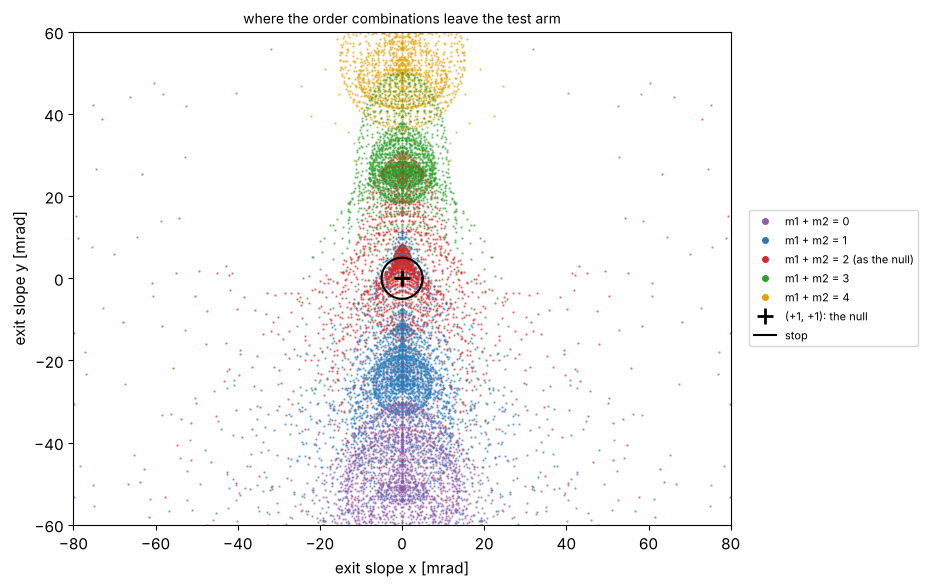

In [8]:
MAX_SLOPE = 2.5/500
t = time.time()
paths = cgh.order_paths(T0, (CGH, 5), orders=range(-2, 4), N=41, max_slope=MAX_SLOPE)
null_rays = next(p for p in paths if p.orders == (1, 1)).passing.sum()
fig, ax = plt.subplots(figsize=(10, 6))
sum_colors = {-2: "#8e5ba8", -1: "#2a7ab9", 0: "#d62728", 1: "#2ca02c", 2: "#e0a000"}
th = np.linspace(0, 2*pi, 200)
for p in paths:
    k = sum(p.orders) - 2
    sl = p.slopes[np.isfinite(p.slopes[:, 0])]
    if p.orders == (1, 1) or k not in sum_colors or not len(sl):
        continue
    ax.plot(1e3*sl[:, 0], 1e3*sl[:, 1], ".", ms=1.5, color=sum_colors[k], alpha=0.5)
for k, c in sum_colors.items():
    ax.plot([], [], ".", ms=8, color=c, label="m1 + m2 = {}{}".format(k + 2, " (as the null)" if k == 0 else ""))
ax.plot([0], [0], "k+", ms=12, mew=2, label="(+1, +1): the null")
ax.plot(1e3*MAX_SLOPE*np.cos(th), 1e3*MAX_SLOPE*np.sin(th), "k-", lw=1.5, label="stop")
ax.set_xlim(-80, 80)
ax.set_ylim(-60, 60)
ax.set_aspect("equal")
ax.set_xlabel("exit slope x [mrad]")
ax.set_ylabel("exit slope y [mrad]")
ax.set_title("where the order combinations leave the test arm", fontsize=10)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
print("{} combinations traced in {:.1f} s".format(len(paths), time.time() - t))
for p in paths:
    if p.passing.any():
        print("  {:>8s}: {:6.1%} of the null's rays pass the stop".format(str(p.orders), p.passing.sum()/null_rays))

The null leaves exactly along the axis (a point at the centre); the
combinations with the same order sum, $(0, 2)$ and $(2, 0)$, straddle the
stop and a third to a half of their light gets through. Combinations with
other order sums lie in rows above and below; $(3, -1)$ and $(-1, 3)$,
order sum 2 as well, catch the stop at the edge of their wide fans.

How bright are they? A binary phase CGH etched to the depth $\pi$ with
duty cycle 1/2 has no even orders (`cgh.binary_orders()`), so $(0, 2)$
vanishes twice. A real CGH is never perfect: with the duty cycle 0.45 and
the depth $0.95\,\pi$ the zeroth order carries 1.6 % and the second order 1 %,
and the third order (3.6 %) pairs with the order -1 to the order sum 2 as well.
The field amplitudes multiply along a path, and an interferogram responds
to the amplitude, not the power, of a ghost:

In [9]:
DUTY, DEPTH = 0.45, 0.95*pi
t_m = dict(zip(range(-2, 4), cgh.binary_orders(range(-2, 4), DUTY, DEPTH)))
for m, t_ in t_m.items():
    print("order {:+d}: efficiency {:6.2%}, phase {:+.3f} rad".format(m, abs(t_)**2, np.angle(t_)))
r_ref = (N_TS - 1)/(N_TS + 1)   # bare fused silica reference surface (amplitude)
r_test = 1.0                     # a coated asphere
amp_null = abs(t_m[1])**2*r_test
for orders in ((0, 2), (2, 0), (3, -1), (-1, 3)):
    a = abs(t_m[orders[0]]*t_m[orders[1]])*r_test
    print("{}: amplitude {:.4f} of the null's ({:.2%})".format(orders, a, a/amp_null))

order -2: efficiency  0.96%, phase +3.063 rad
order -1: efficiency 39.29%, phase +3.063 rad
order +0: efficiency  1.61%, phase +0.588 rad
order +1: efficiency 39.29%, phase +3.063 rad
order +2: efficiency  0.96%, phase +3.063 rad
order +3: efficiency  3.55%, phase -0.079 rad
(0, 2): amplitude 0.0124 of the null's (3.17%)
(2, 0): amplitude 0.0124 of the null's (3.17%)
(3, -1): amplitude 0.1182 of the null's (30.07%)
(-1, 3): amplitude 0.1182 of the null's (30.07%)


**Ghost fringes by field tracing.** The ray picture tells which paths pass;
the camera sees their fields. `fieldtrace.Trace` takes a field through a
`raytrace.System` with ray field summation 
(notebook 463, field tracing applications), so the stop is put into the test arm as a surface
(`cgh.InterferometerStop`, an angular filter in the collimated return beam
that removes the rays outside the pinhole), and a `Parallel` step adds the
reference and all paths with their amplitudes. The field of every arm keeps
its own analytic phase; the detector adds them coherently on the camera
grid.

field traced 6 arms in 10.7 s
ghost phase error 5.7 milliwaves rms (without the 1 % of caustic points: 3.3)


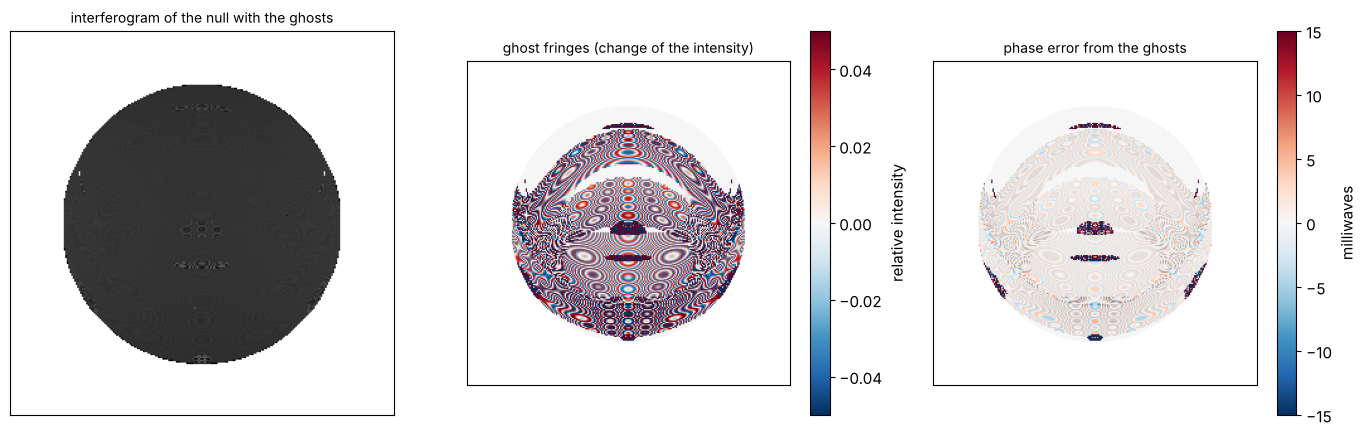

In [10]:
def with_stop(system, orders=None):
    s = [copy.copy(x) for x in system.surfaces]
    if orders is not None:
        s[CGH], s[5] = s[CGH].with_order(orders[0]), s[5].with_order(orders[1])
    s[-1].thickness = DET/2
    s.append(cgh.InterferometerStop(MAX_SLOPE, DET/2, label="stop"))
    return System(s, 0, WL, ray_aiming=False)


xs = np.linspace(-26, 26, 257)
XS, YS = np.meshgrid(xs, xs)
source = ft.from_array((np.hypot(XS, YS) < A - 0.05).astype(complex), xs, xs, wavelength=WL)
ghosts = [(0, 2), (2, 0), (3, -1), (-1, 3)]
arms = ([[ft.Trace(with_stop(reference_arm), distance=5.0, x_out=xc, y_out=xc)],
         [ft.Trace(with_stop(T0), distance=5.0, x_out=xc, y_out=xc)]]
        + [[ft.Trace(with_stop(T0, g), distance=5.0, x_out=xc, y_out=xc)] for g in ghosts])
weights = ([r_ref, t_m[1]**2*r_test]
           + [t_m[g[0]]*t_m[g[1]]*r_test for g in ghosts])
t = time.time()
fields = {}
for name, arm, w in zip(["reference", "null"] + [str(g) for g in ghosts], arms, weights):
    res = ft.Chain(arm + [ft.Detector("camera", quantities=("E",), x=xc, y=xc)]).run(source)
    fields[name] = w*np.nan_to_num(res["camera"].E[0])
print("field traced {} arms in {:.1f} s".format(len(arms), time.time() - t))

E_clean = fields["reference"] + fields["null"]
E_ghost = E_clean + sum(fields[str(g)] for g in ghosts)
phase_err = np.angle(E_ghost*np.conj(E_clean))
# the ray field sum of a ghost overshoots at its caustics (isolated points): robust statistics
err_pupil = phase_err[pupil]
core = np.abs(err_pupil) <= np.percentile(np.abs(err_pupil), 99)
ghost_rms = np.std(err_pupil[core])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
axes[0].imshow(np.where(pupil, np.abs(E_ghost)**2, np.nan), extent=ext, origin="lower", cmap="gray")
axes[0].set_title("interferogram of the null with the ghosts", fontsize=10)
dI = np.where(pupil, np.abs(E_ghost)**2 - np.abs(E_clean)**2, np.nan)/np.mean(np.abs(E_clean[pupil])**2)
im = axes[1].imshow(dI, extent=ext, origin="lower", cmap="RdBu_r", vmin=-0.05, vmax=0.05)
plt.colorbar(im, ax=axes[1], label="relative intensity")
axes[1].set_title("ghost fringes (change of the intensity)", fontsize=10)
im = axes[2].imshow(np.where(pupil, 1e3*phase_err/(2*pi), np.nan), extent=ext, origin="lower", cmap="RdBu_r",
                    vmin=-15, vmax=15)
plt.colorbar(im, ax=axes[2], label="milliwaves")
axes[2].set_title("phase error from the ghosts", fontsize=10)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
print("ghost phase error {:.1f} milliwaves rms (without the 1 % of caustic points: {:.1f})".format(
    1e3*np.std(err_pupil)/(2*pi), 1e3*ghost_rms/(2*pi)))

The null itself is a uniform field (no fringes); the ghosts add rings and
bands of a few percent contrast, and the phase error they cause oscillates
with them. The bright points are the caustics of the ghost paths, where
the ray field sum of `fieldtrace.Trace` overshoots; they are left out of
the statistics. A few milliwaves of phase are a nanometre on the surface,
more than a good asphere test allows. Remedies: a better etch (depth and duty cycle closer to nominal), a
smaller stop, a larger carrier, or some defocus (a "power carrier") that
spreads $(0, 2)$ and $(2, 0)$ further.

## 4. Alignment zones

The null phase only works with the CGH in the right place relative to the
TS focus, and with the asphere in the right place relative to the CGH.
Both are set with extra zones on the same substrate, written in the same
run as the null pattern, so their positions are as good as the writer. The
TS beam is wider than the null region on the CGH; the rim takes two rings:

- a **Littrow ring** (`cgh.retro_phase()`): a reflective pattern whose
  order $m$ sends the incoming converging wave back on itself. Its fringes
  measure the tilt, decentre and axial position of the CGH relative to the
  TS. In the converging beam it needs very fine lines; in the third
  order they are three times coarser;
- a **cat's eye ring** (`cgh.focus_phase()`): a transmissive pattern
  whose order +1 focuses onto the vertex of the asphere. The vertex
  reflects the light like a cat's eye back through the opposite side of
  the ring, where it leaves as the reversed incoming wave (reciprocity).
  A wrong spacing defocuses this null.

In [11]:
_, footprint, _ = cgh.incoming_path(fsys, CGH)
r_beam = np.hypot(*footprint).max()
r_null = np.max(np.hypot(design.x - hologram.centre[0], design.y - hologram.centre[1]))
littrow_ring = (r_null + 0.3, r_null + 0.3 + 0.45*(r_beam - r_null - 0.3))
cat_ring = (littrow_ring[1] + 0.1, r_beam - 0.05)
print("beam on the CGH: radius {:.2f} mm; null region {:.2f} mm; Littrow ring {:.2f}-{:.2f} mm; "
      "cat's eye ring {:.2f}-{:.2f} mm".format(r_beam, r_null, *littrow_ring, *cat_ring))

# Littrow: the pattern reflects inside the substrate, in the third order
litt = ZernikePhaseSurface(mirror=True, order=3, semi_diameter=SD_CGH, label="Littrow ring")
front_litt = forward(blank, dz=DZ)[:CGH]
litt_sys = System(front_litt + [litt], 0, WL, entrance_pupil_radius=A, ray_aiming=False)
littrow = cgh.retro_phase(litt_sys, CGH, *littrow_ring, terms=66)

# cat's eye: focus onto the vertex of the asphere
vertex = fsys.frames()[0][ASPHERE][0]
cats_eye = cgh.focus_phase(fsys, CGH, vertex, *cat_ring, terms=136)
for name, z in (("Littrow (m = 3)", littrow), ("cat's eye (m = 1)", cats_eye)):
    print("{:18s}: fit residual {:.1e} waves, smallest period {:.2f} um".format(
        name, z.fit_residual, 1e3*z.surface.local_period(z.x, z.y).min()))

beam on the CGH: radius 20.08 mm; null region 13.02 mm; Littrow ring 13.32-16.36 mm; cat's eye ring 16.46-20.03 mm


Littrow (m = 3)   : fit residual 1.2e-09 waves, smallest period 2.89 um
cat's eye (m = 1) : fit residual 3.6e-10 waves, smallest period 2.03 um


Both zones are traced in their own double pass, with the rays sorted by the
ring they hit (one pattern per trace). The Littrow ring reacts to the CGH
position, the cat's eye ring to the spacing:

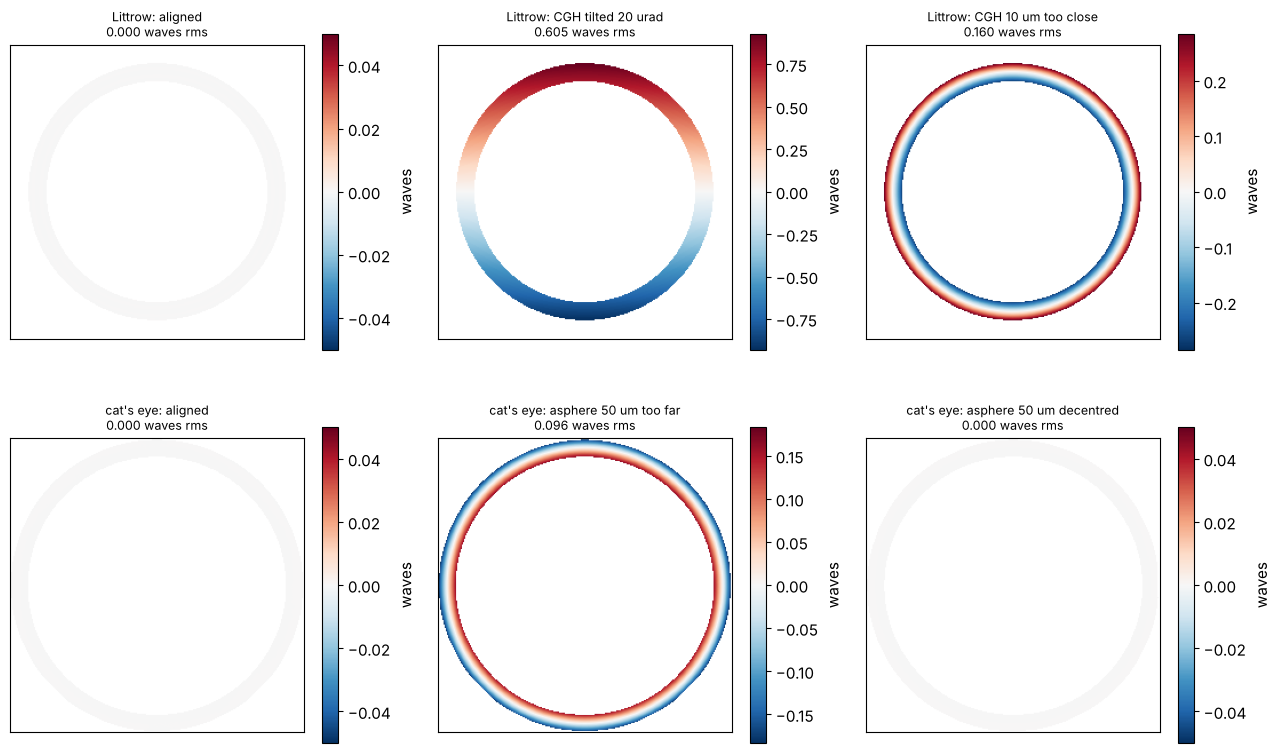

In [12]:
def ring_phase(system, surface_index, ring):
    m = system.ray_map(xc, xc, field=0.0, N=161, surface=surface_index)
    rr = np.hypot(m.points[..., 0], m.points[..., 1])
    sel = m.mask & ref_map.mask & (rr > ring[0]) & (rr < ring[1])
    p = 2*pi*(m.opl - ref_map.opl)/WL
    return np.where(sel, p - np.mean(p[sel]), np.nan), sel


def littrow_arm(tilt=0.0, dz=0.0):
    s = [copy.copy(x) for x in front_litt] + [copy.copy(littrow.surface)]
    s[1].thickness += dz            # move the CGH along the axis
    s[2].tilt = (tilt, 0.0, 0.0)    # tilt the substrate ...
    s[3].tilt = (tilt, 0.0, 0.0)    # ... with its pattern
    return System(double_pass(s, image_distance=DET), 0, WL, ray_aiming=False)


cases = [("Littrow: aligned", ring_phase(littrow_arm(), CGH, littrow_ring)),
         ("Littrow: CGH tilted 20 urad", ring_phase(littrow_arm(tilt=2e-5), CGH, littrow_ring)),
         ("Littrow: CGH 10 um too close", ring_phase(littrow_arm(dz=-1e-2), CGH, littrow_ring)),
         ("cat's eye: aligned", ring_phase(test_arm(cats_eye.surface, dz=DZ), CGH, cat_ring)),
         ("cat's eye: asphere 50 um too far", ring_phase(test_arm(cats_eye.surface, dz=DZ + 0.05), CGH, cat_ring)),
         ("cat's eye: asphere 50 um decentred", ring_phase(test_arm(cats_eye.surface, dz=DZ, decenter=(0.05, 0)),
                                                           CGH, cat_ring))]
fig, axes = plt.subplots(2, 3, figsize=(13, 8.3))
for ax, (title, (p, sel)) in zip(axes.flat, cases):
    lim = max(0.05, np.nanmax(np.abs(p))/(2*pi))
    im = ax.imshow(p/(2*pi), extent=ext, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
    plt.colorbar(im, ax=ax, label="waves", shrink=0.8)
    ax.set_title("{}\n{:.3f} waves rms".format(title, np.nanstd(p)/(2*pi)), fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()

The Littrow ring is extremely sensitive to the CGH position (more than
half a wave of tilt for 20 µrad, power for a few micrometres), as it should be: the null phase
holds only for the CGH where it was designed. The cat's eye ring sees the
spacing (defocus, though weakly: its rays meet the vertex at small angles,
so a shift along the axis changes their paths only by the cosine of those
angles) and not at all a lateral shift of the asphere: at the vertex a
small decentre only slides the surface in its own tangent plane. The
lateral position of the asphere comes from the null region itself (coma
and tilt, section 6), or from fiducials projected onto the asphere's rim
by further focusing zones.

The complete CGH as the writer sees it: the line density of the null
region and the two rings, and the binary lines at the border between the
null region and the Littrow ring and in the cat's eye ring:

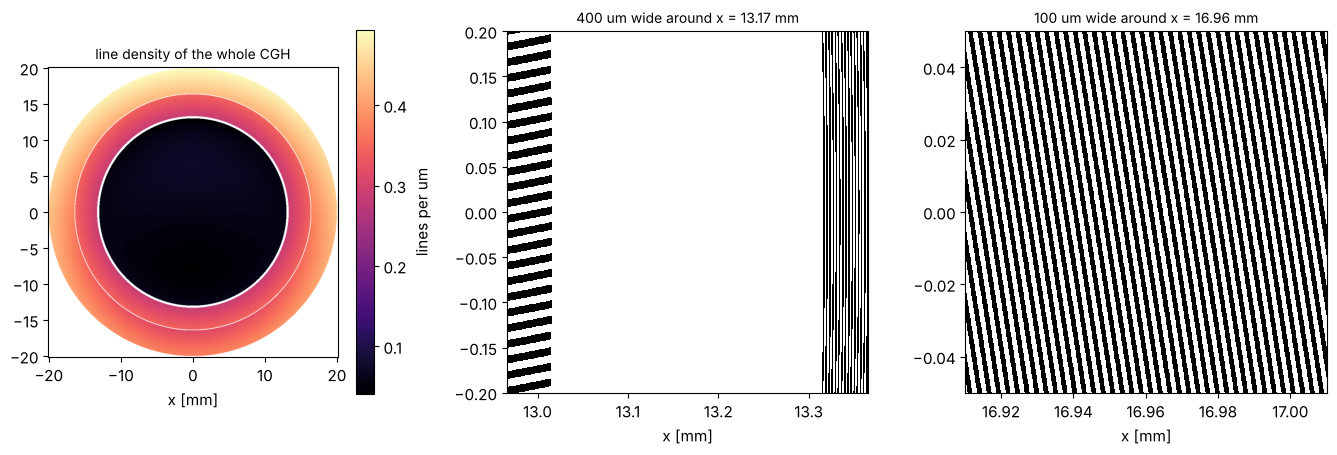

In [13]:
def full_phase(x, y):
    r_ = np.hypot(x, y)
    p = np.full(np.shape(x), np.nan)
    for (lo, hi), surf in (((0.0, r_null), hologram), (littrow_ring, littrow.surface),
                           (cat_ring, cats_eye.surface)):
        sel = (r_ >= lo) & (r_ <= hi)
        p[sel] = surf.phase_at(x[sel], y[sel])
    return p


fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
for ax, (cx, half) in zip(axes, ((0.0, r_beam), (r_null + 0.15, 0.2), (cat_ring[0] + 0.5, 0.05))):
    g = np.linspace(cx - half, cx + half, 900)
    GX, GY = np.meshgrid(g, np.linspace(-half, half, 900))
    p = full_phase(GX, GY)
    img = np.where(np.isfinite(p), cgh.binary_mask(np.nan_to_num(p)), np.nan)
    if half > 5:   # too fine to show: the local line density instead
        pl = np.where(np.hypot(GX, GY) <= r_null, 1/(1e3*hologram.local_period(GX, GY)), np.nan)
        pl = np.where((np.hypot(GX, GY) >= littrow_ring[0]) & (np.hypot(GX, GY) <= littrow_ring[1]),
                      1/(1e3*littrow.surface.local_period(GX, GY)), pl)
        pl = np.where((np.hypot(GX, GY) >= cat_ring[0]) & (np.hypot(GX, GY) <= cat_ring[1]),
                      1/(1e3*cats_eye.surface.local_period(GX, GY)), pl)
        im = ax.imshow(pl, extent=[g[0], g[-1], -half, half], origin="lower", cmap="magma")
        plt.colorbar(im, ax=ax, label="lines per um")
        ax.set_title("line density of the whole CGH", fontsize=10)
    else:
        ax.imshow(img, extent=[g[0], g[-1], -half, half], origin="lower", cmap="gray_r", interpolation="none")
        ax.set_title("{:.0f} um wide around x = {:.2f} mm".format(2e3*half, cx), fontsize=10)
    ax.set_xlabel("x [mm]")
plt.tight_layout()

## 5. The measurement

Now a real asphere: it has a form error (astigmatism, spherical
aberration, trefoil and a higher order term, in Fringe Zernikes of the sag
over the clear aperture, traced exactly as a `ZernikeSurface`) and a
mid-spatial ripple from the polishing tool (added to first order as a phase
at the ray footprints), and it is placed a little off: 20 µm and -15 µm
decentred, tilted by 0.1 and -0.05 mrad, 10 µm too far from the CGH. A
phase shifting measurement (Hariharan's five frames,
notebook 500, interferometry) with camera noise gives the wrapped phase, which is
unwrapped.

measured phase 44.63 waves PV; PSI + noise error 0.0011 waves rms


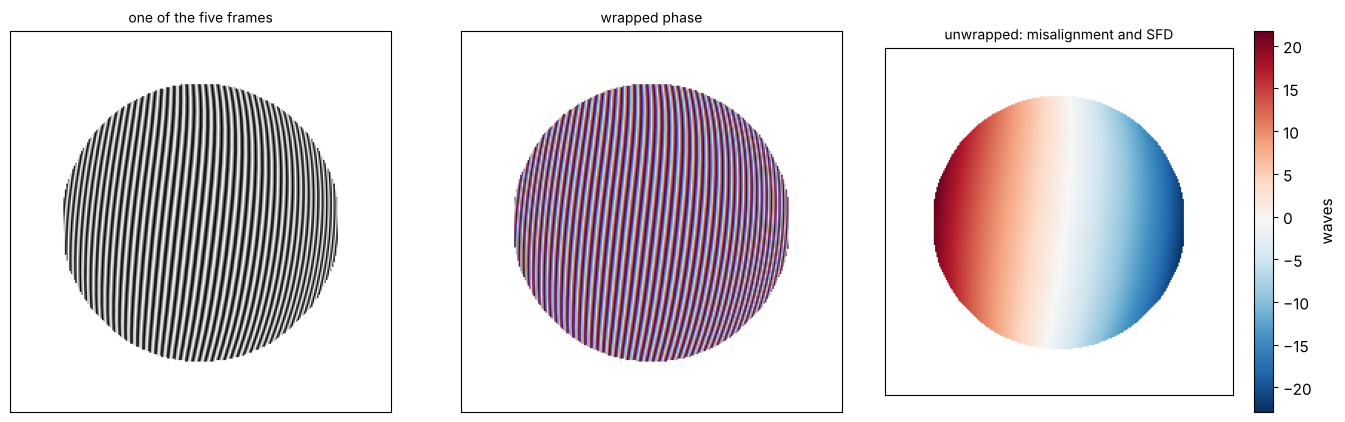

In [14]:
SFD = {5: 30e-6, 9: -20e-6, 10: 15e-6, 16: 10e-6}   # sag in mm (Fringe Zernikes over the clear aperture)
RIPPLE, RIPPLE_PERIOD = 2e-6, 4.0                   # 2 nm, 4 mm period, radial
MISALIGN = dict(decenter=(0.02, -0.015), tilt=(1e-4, -5e-5), dz=0.01)


def ripple(u, v):
    return RIPPLE*np.cos(2*pi*np.hypot(u, v)/RIPPLE_PERIOD)


def measured_phase(sfd=SFD, misalign=MISALIGN, with_ripple=True):
    kw = dict(misalign)
    T = test_arm(hologram, dz=DZ + kw.pop("dz", 0.0), sfd=sfd, **kw)
    m = T.ray_map(xc, xc, field=0.0, N=161, surface=ASPHERE)
    p = 2*pi*(m.opl - ref_map.opl)/WL
    if with_ripple:
        o, R = T.frames()[0][ASPHERE]
        P = (m.points - o) @ R
        # a ripple of height h (sag, i.e. a dip for h > 0 seen from the light) lengthens
        # the path by 2 h cos(normal angle) ~ 2 h
        p = p + 2*2*pi/WL*np.nan_to_num(ripple(P[..., 0], P[..., 1]))
    return p, m, T


phi_true, m_true, T_true = measured_phase()
ok = pupil & m_true.mask
I0, VIS = 1.0, 0.95
shifts = phase_shifts(5, step=pi/2, start=-pi)
rng = np.random.default_rng(3)
frames = interferogram(np.where(ok, phi_true - np.mean(phi_true[ok]), 0.0), visibility=VIS, I0=I0, shift=shifts,
                       noiser=CameraNoiser("gaussian", sigma=0.005, relative=True, rng=rng))
wrapped, modulation = psi_hariharan(frames)
phi_meas = unwrap(np.where(ok, wrapped, 0.0), mask=ok)
phi_meas = np.where(ok, phi_meas, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
axes[0].imshow(np.where(ok, frames[..., 2], np.nan), extent=ext, origin="lower", cmap="gray")
axes[0].set_title("one of the five frames", fontsize=10)
axes[1].imshow(np.where(ok, wrapped, np.nan), extent=ext, origin="lower", cmap="twilight")
axes[1].set_title("wrapped phase", fontsize=10)
im = axes[2].imshow(phi_meas/(2*pi), extent=ext, origin="lower", cmap="RdBu_r")
plt.colorbar(im, ax=axes[2], label="waves")
axes[2].set_title("unwrapped: misalignment and SFD", fontsize=10)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
err = phi_meas - (phi_true - np.mean(phi_true[ok]))
print("measured phase {:.2f} waves PV; PSI + noise error {:.4f} waves rms".format(
    np.nanmax(phi_meas)/(2*pi) - np.nanmin(phi_meas)/(2*pi), np.nanstd(err - np.nanmean(err))/(2*pi)))

## 6. Reconstructing the surface form deviation

**Misalignment.** The measured phase is dominated by the misalignment.
For a sphere, decentre and tilt are the same thing (tilt fringes) and the
axial shift is defocus. For an asphere in a null test they differ: a
decentred asphere shows coma (and tilt), a tilted one tilt plus coma of the
opposite proportion, an axial shift defocus plus spherical aberration,
all in the distorted coordinates of the camera. The exact signatures come
from the same ray trace: the phase per unit displacement of each degree of
freedom, by finite differences (`cgh.remove_alignment()` fits them with
piston):

decenter x : fitted +0.02007, true +0.02000
decenter y : fitted -0.01486, true -0.01500
tilt x     : fitted +0.00010, true +0.00010
tilt y     : fitted -0.00005, true -0.00005
spacing    : fitted +0.00976, true +0.01000


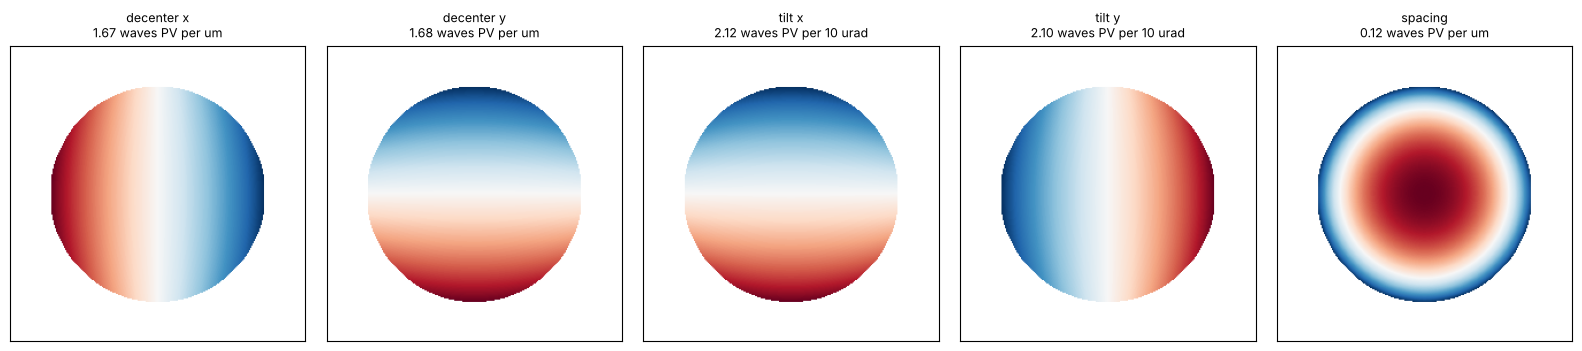

In [15]:
STEPS = {"decenter x": dict(decenter=(1e-3, 0.0)), "decenter y": dict(decenter=(0.0, 1e-3)),
         "tilt x": dict(tilt=(1e-5, 0.0)), "tilt y": dict(tilt=(0.0, 1e-5)), "spacing": dict(dz=1e-3)}
UNITS = {"decenter x": 1e-3, "decenter y": 1e-3, "tilt x": 1e-5, "tilt y": 1e-5, "spacing": 1e-3}


def phase_of(**kw):
    dz = kw.pop("dz", 0.0)
    m = test_arm(hologram, dz=DZ + dz, **kw).ray_map(xc, xc, field=0.0, N=161, surface=ASPHERE)
    return 2*pi*(m.opl - ref_map.opl)/WL


sens = {name: (phase_of(**kw) - phi0)/UNITS[name] for name, kw in STEPS.items()}
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, (name, S) in zip(axes, sens.items()):
    unit = "um" if name != "tilt x" and name != "tilt y" else "10 urad"
    scale = 1e-3 if unit == "um" else 1e-5
    ax.imshow(np.where(pupil, S*scale/(2*pi), np.nan), extent=ext, origin="lower", cmap="RdBu_r")
    ax.set_title("{}\n{:.2f} waves PV per {}".format(name, np.nanmax(S[pupil]*scale)/(2*pi)
                                                     - np.nanmin(S[pupil]*scale)/(2*pi), unit), fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()

p_fit, residual = cgh.remove_alignment(phi_meas, list(sens.values()), mask=ok)
truth = [MISALIGN["decenter"][0], MISALIGN["decenter"][1], MISALIGN["tilt"][0], MISALIGN["tilt"][1],
         MISALIGN["dz"]]
for name, a, b in zip(sens, p_fit, truth):
    print("{:11s}: fitted {:+.5f}, true {:+.5f}".format(name, a, b))

**From the camera to the surface.** What is left is the form error, in
camera coordinates. Every camera pixel belongs to the ray that met the
asphere at one point (`System.ray_map(..., surface=...)` returns those
points), and the phase there is $-2k h$ for a surface error $h$ along the
normal (a bump towards the light shortens the path twice). `cgh.surface_map()`
does both and converts $h$ into an error of the sag. The mapping is far
from linear: the null bends the rays strongly, the CGH (and the camera) see
the rim of the asphere compressed, and inverted, since the rays cross in the
focus between the CGH and the asphere.

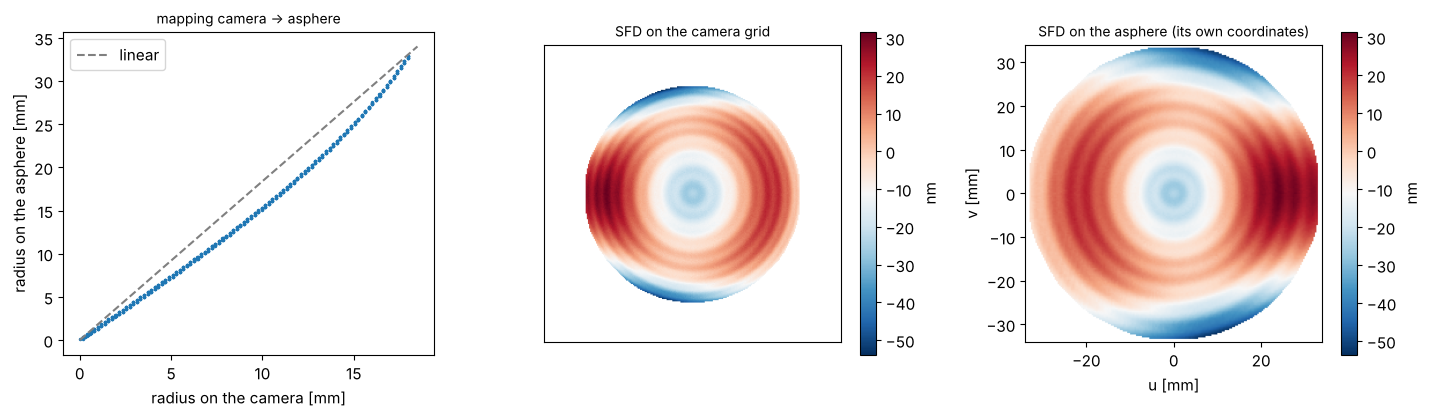

In [16]:
surf = cgh.surface_map(residual, m_true, T_true, ASPHERE)
rc = np.hypot(XC, YC)
rs = np.hypot(surf.u, surf.v)
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.3))
sel = surf.mask & (np.abs(YC) < 0.2)
axes[0].plot(rc[sel], rs[sel], ".", ms=3)
axes[0].plot([0, rc[surf.mask].max()], [0, A_TEST], "--", color="0.5", label="linear")
axes[0].set_xlabel("radius on the camera [mm]")
axes[0].set_ylabel("radius on the asphere [mm]")
axes[0].legend()
axes[0].set_title("mapping camera -> asphere", fontsize=10)
im = axes[1].imshow(np.where(surf.mask, 1e6*surf.sag, np.nan), extent=ext, origin="lower", cmap="RdBu_r")
plt.colorbar(im, ax=axes[1], label="nm")
axes[1].set_title("SFD on the camera grid", fontsize=10)
axes[1].set_xticks([])
axes[1].set_yticks([])
from scipy.interpolate import griddata
ug = np.linspace(-A_TEST, A_TEST, 201)
UG, VG = np.meshgrid(ug, ug)
on_surface = griddata((surf.u[surf.mask], surf.v[surf.mask]), 1e6*surf.sag[surf.mask], (UG, VG))
im = axes[2].imshow(np.where(np.hypot(UG, VG) <= A_TEST, on_surface, np.nan),
                    extent=[ug[0], ug[-1], ug[0], ug[-1]], origin="lower", cmap="RdBu_r")
plt.colorbar(im, ax=axes[2], label="nm")
axes[2].set_aspect("equal")
axes[2].set_title("SFD on the asphere (its own coordinates)", fontsize=10)
axes[2].set_xlabel("u [mm]")
axes[2].set_ylabel("v [mm]")
plt.tight_layout()

Zernikes of the SFD belong to the surface coordinates. Fitting them in
camera coordinates (normalized to the edge of the pupil, as an
interferometer without the mapping would) mixes the terms: the radial
compression turns spherical aberration into a blend of $Z_9$, $Z_{16}$ and
defocus.

asphere coordinates: Z4 -5.41, Z5 +28.94, Z9 -20.21, Z10 +14.99, Z16 +9.88
residual after 36 Zernikes: 1.47 nm rms (the ripple has 1.41 nm rms)


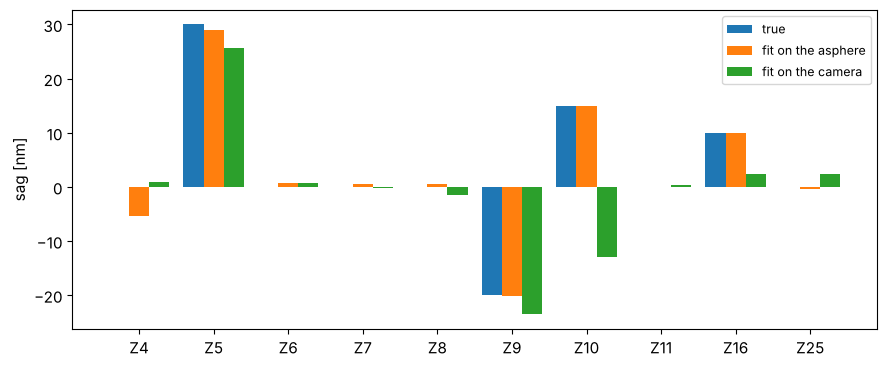

In [17]:
J = 36
c_surf, res_surf, _ = cgh.zernike_fit(surf.u, surf.v, 1e6*surf.sag, norm_radius=A_TEST, terms=J, mask=surf.mask)
r_pupil = rc[surf.mask].max()
c_cam, _, _ = cgh.zernike_fit(XC, YC, 1e6*surf.sag, norm_radius=r_pupil, terms=J, mask=surf.mask)
shown = [4, 5, 6, 7, 8, 9, 10, 11, 16, 25]
fig, ax = plt.subplots(figsize=(9, 3.8))
w = 0.27
xs_ = np.arange(len(shown))
ax.bar(xs_ - w, [1e6*SFD.get(j, 0.0) for j in shown], w, label="true")
ax.bar(xs_, [c_surf[j] for j in shown], w, label="fit on the asphere")
ax.bar(xs_ + w, [c_cam[j] for j in shown], w, label="fit on the camera")
ax.set_xticks(xs_)
ax.set_xticklabels(["Z{}".format(j) for j in shown])
ax.set_ylabel("sag [nm]")
ax.legend(fontsize=9)
plt.tight_layout()
print("asphere coordinates: " + ", ".join("Z{} {:+.2f}".format(j, c_surf[j]) for j in (4, 5, 9, 10, 16)))
print("residual after {} Zernikes: {:.2f} nm rms (the ripple has {:.2f} nm rms)".format(
    J, np.nanstd(res_surf), 1e6*RIPPLE/np.sqrt(2)))

In the asphere's coordinates the fit returns the form error to a few
percent and the ripple stays in the residual. Two things are left over:

- **Power is not measured.** $Z_4$ came out at a few nanometres although
  the asphere has none: a change of the vertex radius and a change of the
  spacing look almost alike, and the fit of the spacing took part of the
  spherical aberration. Null tests report the SFD without power (or with
  the radius measured separately, as in notebook 502,
  radius interferometer).
- **Second order misalignment.** The sensitivities are linear. The
  astigmatism is off by a nanometre because a tilted and decentred asphere
  adds aberrations that grow with the square of the misalignment, the same
  physics as the retrace error. With the fitted misalignment, one more step
  linearizes around the right place (Gauss-Newton): trace the asphere at
  the fitted position, subtract, fit again.

In [18]:
def misalign_of(p):
    return dict(decenter=(p[0], p[1]), tilt=(p[2], p[3]), dz=p[4])


def reconstruct(phi, p_start, iterations=1):
    p = np.array(p_start, dtype=float)
    for _ in range(iterations):
        # model of the aligned-to-p asphere without SFD, and its sensitivities there
        base = phase_of(**misalign_of(p))
        d, res = cgh.remove_alignment(phi - base, list(sens.values()), mask=ok)
        p = p + d
    return p, res


rows = []
for scale in (0.5, 1.0, 2.0, 4.0):
    mis = {k: (tuple(scale*np.array(v)) if np.ndim(v) else scale*v) for k, v in MISALIGN.items()}
    phi_s, m_s, T_s = measured_phase(misalign=mis, with_ripple=False)
    p1, r1 = cgh.remove_alignment(phi_s, list(sens.values()), mask=ok)
    p2, r2 = reconstruct(phi_s, p1)
    out = []
    for r_ in (r1, r2):
        sm = cgh.surface_map(r_, m_s, T_s, ASPHERE)
        cz, _, _ = cgh.zernike_fit(sm.u, sm.v, 1e6*sm.sag, norm_radius=A_TEST, terms=J, mask=sm.mask)
        out.append(cz)
    sm1 = cgh.surface_map(r1, m_s, T_s, ASPHERE)
    sm2 = cgh.surface_map(r2, m_s, T_s, ASPHERE)
    _, d1, _ = cgh.zernike_fit(sm1.u, sm1.v, 1e6*sm1.sag, norm_radius=A_TEST, terms=4, mask=sm1.mask)
    _, d2, _ = cgh.zernike_fit(sm2.u, sm2.v, 1e6*sm2.sag, norm_radius=A_TEST, terms=4, mask=sm2.mask)
    rows.append((scale, out, np.nanstd(d1 - d2)))
print("misalignment x  | Z5 linear / iterated | Z9 linear / iterated  (true {:+.0f} / {:+.0f} nm)".format(
    1e6*SFD[5], 1e6*SFD[9]))
for scale, (a, b), _ in rows:
    print("      {:4.1f}      |  {:+7.2f} / {:+7.2f}    | {:+7.2f} / {:+7.2f}".format(scale, a[5], b[5], a[9], b[9]))

misalignment x  | Z5 linear / iterated | Z9 linear / iterated  (true +30 / -20 nm)
       0.5      |   +29.75 /  +30.00    |  -19.97 /  -19.88
       1.0      |   +28.90 /  +30.00    |  -20.22 /  -19.88
       2.0      |   +25.46 /  +29.98    |  -21.26 /  -19.88
       4.0      |   +11.37 /  +29.80    |  -25.53 /  -19.86


The linear fit degrades quadratically with the misalignment (four times
the misalignment: astigmatism off by about 60 %); one iteration restores the
form error to a few tenths of a nanometre even there. In the lab, the operator
realigns until the fitted misalignment is small, which has the same
effect; the iteration does it in software.

## 7. Error budget of the CGH

The CGH is the reference of the test: what is wrong with it appears as a
surface error. The main contributions (Chang and Burge 1999, Zhou and
Burge 2007):

**Line placement (writer distortion).** Lines displaced by $\epsilon$
change the phase of the order $m$ by $-m\nabla\varphi\cdot\epsilon$ per
pass (`cgh.distortion_phase()`): the error is the displacement as a
fraction of the local period, so it is largest where the lines are densest.
A writer with a 50 nm scale error over the plate (a stretch proportional
to the position) and a 20 nm ripple:

writer error: 0.10 nm rms apparent surface error


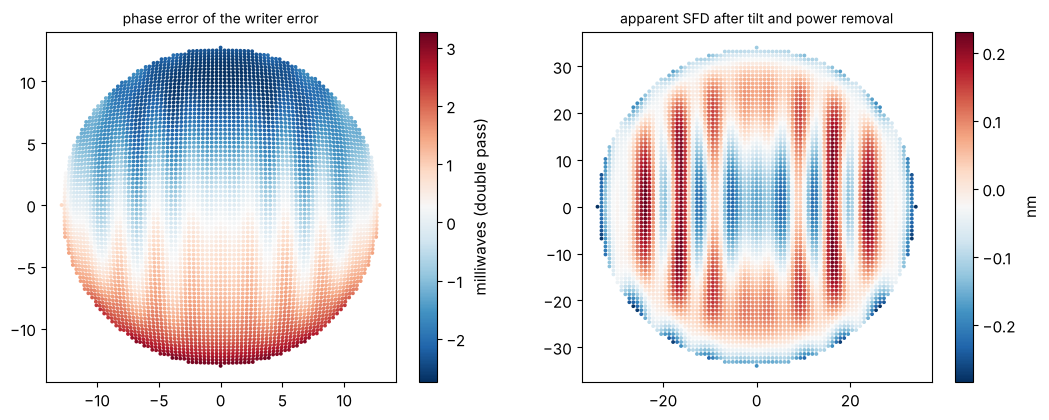

In [19]:
def writer_error(x, y):
    scale = 50e-6/SD_CGH                       # 50 nm over the plate radius
    wobble = 20e-6*np.sin(2*pi*x/3.0)           # 20 nm, 3 mm period, along x
    return scale*x + wobble, scale*y


gx_, gy_ = design.x, design.y
dphi = cgh.distortion_phase(hologram, gx_, gy_, writer_error, passes=2)
# the scale part is mostly tilt and power (removed as alignment); report the rest
c_d, r_d, _ = cgh.zernike_fit(gx_, gy_, dphi, terms=4, ordering="fringe", centre=hologram.centre)
pts = design.test_points
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sc = axes[0].scatter(gx_, gy_, c=1e3*dphi/(2*pi), s=3, cmap="RdBu_r")
plt.colorbar(sc, ax=axes[0], label="milliwaves (double pass)")
axes[0].set_title("phase error of the writer error", fontsize=10)
sc = axes[1].scatter(pts[:, 0], pts[:, 1], c=-1e6*WL*r_d/(4*pi), s=3, cmap="RdBu_r")
plt.colorbar(sc, ax=axes[1], label="nm")
axes[1].set_title("apparent SFD after tilt and power removal", fontsize=10)
for ax in axes:
    ax.set_aspect("equal")
plt.tight_layout()
sfd_writer = np.std(WL*r_d/(4*pi))
print("writer error: {:.2f} nm rms apparent surface error".format(1e6*sfd_writer))

The carrier dominates the gradient, so a placement error along the
carrier (y) costs most; the 20 nm wobble along x mostly runs along the
lines where they are nearly parallel to x, and so costs little.

**Etch depth and duty cycle.** In the thin element model the phase of the
order +1 of a binary grating is depth/2 + π/2 (`cgh.binary_orders()`):
a depth that varies over the plate writes half its phase error into each
pass, independent of the duty cycle. The rigorous model (`cgh.binary_orders_rcwa()`,
`litho.rcwa` for the lines etched into fused silica) agrees for wide lines;
for periods of a few wavelengths, the phase depends on the duty cycle as
well:

depth +2 % / -2 %: phase of +1 changes by +4.99 / -4.99 milliwaves per pass (scalar: +-5.00)


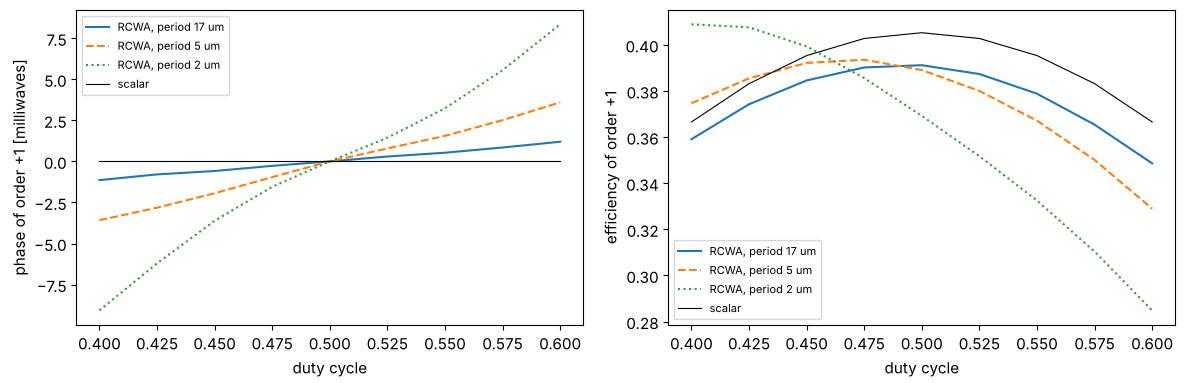

In [20]:
n_fs = N_TS
h_pi = WL/(2*(n_fs - 1))
duties = np.linspace(0.4, 0.6, 9)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for P, ls in ((16.7e-3, "-"), (5e-3, "--"), (2e-3, ":")):
    ph = [np.angle(cgh.binary_orders_rcwa(P, D, h_pi, WL, n_fs, orders=(1,))[0]) for D in duties]
    eta = [abs(cgh.binary_orders_rcwa(P, D, h_pi, WL, n_fs, orders=(1,))[0])**2 for D in duties]
    axes[0].plot(duties, 1e3*(np.unwrap(ph) - np.unwrap(ph)[4])/(2*pi), ls, label="RCWA, period {:.0f} um".format(1e3*P))
    axes[1].plot(duties, eta, ls, label="RCWA, period {:.0f} um".format(1e3*P))
axes[0].plot(duties, 0*duties, "k-", lw=0.8, label="scalar")
axes[1].plot(duties, np.abs(cgh.binary_orders(np.ones_like(duties), duties, pi))**2, "k-", lw=0.8, label="scalar")
axes[0].set_xlabel("duty cycle")
axes[0].set_ylabel("phase of order +1 [milliwaves]")
axes[1].set_xlabel("duty cycle")
axes[1].set_ylabel("efficiency of order +1")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()

depths = np.array([0.98, 1.0, 1.02])*h_pi
t_d = [cgh.binary_orders_rcwa(16.7e-3, 0.5, d_, WL, n_fs, orders=(1,))[0] for d_ in depths]
dph = [np.angle(t_*np.conj(t_d[1])) for t_ in t_d]
print("depth +2 % / -2 %: phase of +1 changes by {:+.2f} / {:+.2f} milliwaves per pass (scalar: +-{:.2f})".format(
    1e3*dph[2]/(2*pi), 1e3*dph[0]/(2*pi), 1e3*0.02*pi/2/(2*pi)))

At the 13 to 25 µm periods of this CGH the duty cycle is nearly harmless
(about a milliwave over ±10 %), but a 2 % depth variation over the plate
costs 5 milliwaves per pass, 10 milliwaves in the double pass, i.e. 3 nm of
surface. The depth must be uniform to a few nanometres, or the CGH is
calibrated. The efficiency itself drops by a few percent from the Fresnel
reflections, which only costs contrast.

**The substrate.** The test wave passes the substrate twice; a thickness
variation $\Delta t$ adds $2(n-1)\Delta t$ to the path, i.e. $(n-1)\Delta t$
to the apparent surface. A plate polished to 30 nm PV transmitted
wavefront is then good for about 15 nm on the asphere, unless it is
measured in the zero order (the substrate alone, with the asphere replaced
by a sphere) and subtracted. The Littrow and cat's eye zones are written
in the same run, so their errors are those of the writer.

**Summary of the budget** (rms on the asphere, for this example):

In [21]:
# surface (nm rms) from a double pass phase (rad): h = phase*lambda/(4 pi)
to_nm = 1e6*WL/(4*pi)
budget = [
    ("CGH design (Zernike fit, 231 terms; 2 passes)", to_nm*2*2*pi*design.fit_residual),
    ("writer: 50 nm scale + 20 nm ripple", 1e6*sfd_writer),
    ("etch depth: 1 % rms over the plate (2 passes)", to_nm*2*0.01*pi/2),
    ("ghost orders (duty 0.45, depth 0.95 pi)", to_nm*ghost_rms),
    ("PSI with camera noise", to_nm*np.nanstd(err - np.nanmean(err))),
    ("misalignment x1, linear fit (iterated: ~0)", rows[1][2]),
]
total = np.sqrt(sum(v**2 for _, v in budget))
for name, v in budget:
    print("{:46s} {:6.3f} nm".format(name, v))
print("{:46s} {:6.3f} nm".format("RSS", total))
print("\nnotebook ran in {:.0f} s".format(time.time() - T_START))

CGH design (Zernike fit, 231 terms; 2 passes)   0.000 nm
writer: 50 nm scale + 20 nm ripple              0.102 nm
etch depth: 1 % rms over the plate (2 passes)   1.582 nm
ghost orders (duty 0.45, depth 0.95 pi)         1.057 nm
PSI with camera noise                           0.341 nm
misalignment x1, linear fit (iterated: ~0)      0.472 nm
RSS                                             1.992 nm

notebook ran in 81 s


The CGH itself, written and etched well, is a reference at the nanometre
level; its ghosts and the depth uniformity are what need care.

## Summary

- An asphere that departs by tens of waves from its best fit sphere cannot
  be measured against a sphere: the fringes alias and retrace errors spoil
  the cancellation of the interferometer's errors.
- `cgh.null_phase()` designs the null hologram without optimization: the
  normals of the asphere cast back onto the CGH and the traced incoming
  wave give the phase exactly; Zernikes to radial order 20 fit it to
  $10^{-6}$ waves, verified by tracing the double pass
  (`raytrace.ZernikePhaseSurface`, `raytrace.double_pass()`).
- The spacing is chosen for the smallest line frequency besides the
  carrier; the tilt carrier separates all order combinations except those
  with the same order sum. `cgh.order_paths()` shows which ones reach the
  stop, `cgh.InterferometerStop` puts the stop into the trace, and field
  tracing (`fieldtrace.Trace` per path) turns the survivors into ghost
  fringes and phase errors.
- Alignment zones on the same plate: `cgh.retro_phase()` (Littrow, here
  in the third order) aligns the CGH to the TS, `cgh.focus_phase()` (cat's
  eye on the vertex) sets the spacing.
- Reconstruction: traced misalignment sensitivities instead of Zernike
  alignment terms (`cgh.remove_alignment()`), an iteration for the second
  order, the camera mapped onto the surface (`cgh.surface_map()`) and
  Zernikes fitted there (`cgh.zernike_fit()`). Power stays coupled to
  the spacing.
- Error budget: writer distortion (`cgh.distortion_phase()`), etch depth
  and duty cycle (`cgh.binary_orders()`, `cgh.binary_orders_rcwa()`),
  substrate, ghosts.

## References

- J. C. Wyant and V. P. Bennett, "Using computer generated holograms to
  test aspheric wavefronts", Appl. Opt. 11, 2833-2839 (1972).
- J. H. Burge, "Applications of computer-generated holograms for
  interferometric measurement of large aspheric optics", Proc. SPIE 2576,
  258-269 (1995).
- Y.-C. Chang and J. H. Burge, "Error analysis for CGH optical testing",
  Proc. SPIE 3782, 358-366 (1999).
- P. Zhou and J. H. Burge, "Fabrication error analysis and experimental
  demonstration for computer-generated holograms", Appl. Opt. 46, 657-663
  (2007).
- D. Malacara (ed.), *Optical Shop Testing*, 3rd ed., Wiley (2007),
  chapter 15.
- LightTrans, "Design of a CGH for null-testing", VirtualLab Fusion use
  case USC.0466 (2025).
- F. Wyrowski and M. Kuhn, "Introduction to field tracing", J. Mod. Opt.
  58, 449-466 (2011).